In [ ]:
from google.colab import files
uploaded =files.upload()

Saving CarPrice_Assignment.csv to CarPrice_Assignment (1).csv


In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
df = pd.read_csv("CarPrice_Assignment.csv")

print(df)


     car_ID  symboling                   CarName fueltype aspiration  \
0         1          3        alfa-romero giulia      gas        std   
1         2          3       alfa-romero stelvio      gas        std   
2         3          1  alfa-romero Quadrifoglio      gas        std   
3         4          2               audi 100 ls      gas        std   
4         5          2                audi 100ls      gas        std   
..      ...        ...                       ...      ...        ...   
200     201         -1           volvo 145e (sw)      gas        std   
201     202         -1               volvo 144ea      gas      turbo   
202     203         -1               volvo 244dl      gas        std   
203     204         -1                 volvo 246   diesel      turbo   
204     205         -1               volvo 264gl      gas      turbo   

    doornumber      carbody drivewheel enginelocation  wheelbase  ...  \
0          two  convertible        rwd          front       88

In [ ]:
df.head()

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


In [ ]:
df.shape

(205, 26)

In [ ]:
df.columns

Index(['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration',
       'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase',
       'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype',
       'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke',
       'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg',
       'price'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null    object 
 9   wheelbase         205 non-null    float64
 10  carlength         205 non-null    float64
 11  carwidth          205 non-null    float64
 12  carheight         205 non-null    float64
 13  curbweight        205 non-null    int64  
 14  enginetype        205 non-null    object 
 15  cylindernumber    205 non-null    object 
 16  enginesize        205 non-null    int64  
 1

In [ ]:
df.describe()

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


In [ ]:
df.isnull().sum()

,0
car_ID,0
symboling,0
CarName,0
fueltype,0
aspiration,0
doornumber,0
carbody,0
drivewheel,0
enginelocation,0
wheelbase,0


In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
df = df.drop(["car_ID", "CarName"], axis=1)

In [ ]:
X = df.drop("price", axis=1)

y = df["price"]

In [ ]:
categorical = X.select_dtypes(
    include=["object"]
).columns

numerical = X.select_dtypes(
    exclude=["object"]
).columns

preprocessor = ColumnTransformer([
    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical),

    ("numerical", "passthrough", numerical)
])

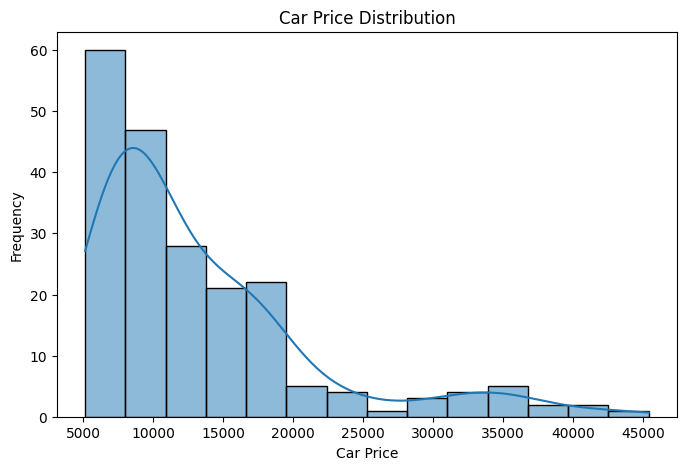

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["price"], kde=True)

plt.title("Car Price Distribution")
plt.xlabel("Car Price")
plt.ylabel("Frequency")

plt.show()

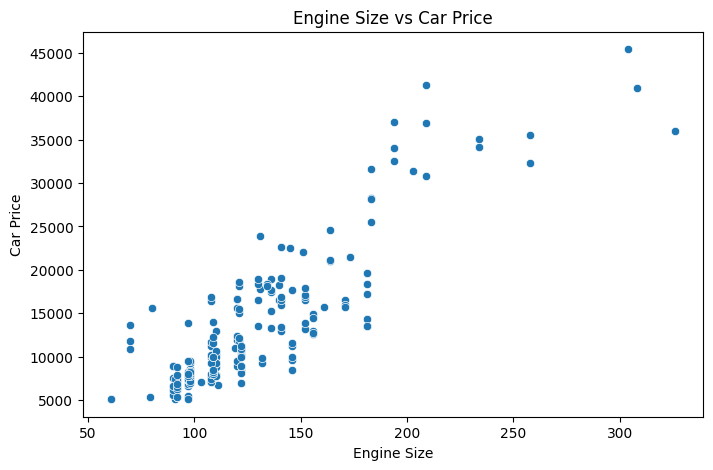

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["enginesize"],
    y=df["price"]
)

plt.title("Engine Size vs Car Price")
plt.xlabel("Engine Size")
plt.ylabel("Car Price")

plt.show()

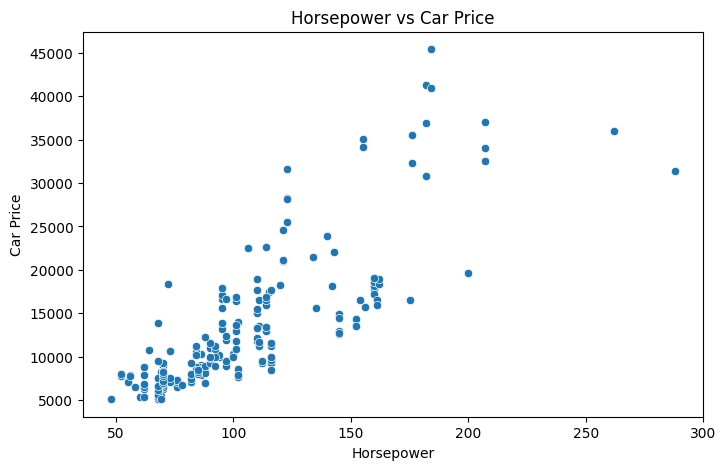

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df["horsepower"],
    y=df["price"]
)

plt.title("Horsepower vs Car Price")
plt.xlabel("Horsepower")
plt.ylabel("Car Price")

plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
print(X_train.shape)
print(X_test.shape)

(164, 23)
(41, 23)


In [ ]:
models = {

    "Linear Regression":
    LinearRegression(),

    "Decision Tree":
    DecisionTreeRegressor(random_state=42),

    "Random Forest":
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting":
    GradientBoostingRegressor(random_state=42)
}

In [ ]:
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(
        y_test, predictions
    )

    mse = mean_squared_error(
        y_test, predictions
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test, predictions
    )

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df)

           Algorithm          MAE           MSE         RMSE  R2 Score
0  Linear Regression  2244.601726  1.006731e+07  3172.902001  0.872475
1      Decision Tree  1819.422756  7.615889e+06  2759.690054  0.903528
2      Random Forest  1262.691801  3.245162e+06  1801.433317  0.958893
3  Gradient Boosting  1680.590432  5.775711e+06  2403.270910  0.926838


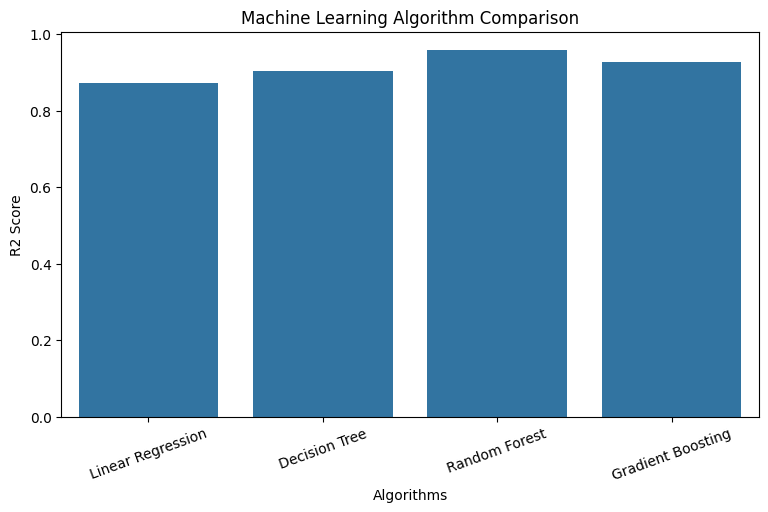

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Algorithm",
    y="R2 Score"
)

plt.title("Machine Learning Algorithm Comparison")

plt.xlabel("Algorithms")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
df = pd.read_csv("CarPrice_Assignment.csv")

print(df.head())

   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrpm citympg  \

In [ ]:
X = df[[
    "enginesize",
    "horsepower",
    "curbweight",
    "citympg",
    "highwaympg"
]]

y = df["price"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test)

print(y_pred)

[26751.75556402 18688.90240736 11318.47853565 13739.55192108
 23497.3462972   6764.91741014  8098.4246225   7485.20817822
 10852.76987612  6847.01655722 14913.91141684  7632.30781409
 15956.04738862 11561.26845965 37385.61596963  6045.14585446
   -61.64888574 18892.2472576  11562.97421923 10338.32100342
 11279.27226695 22401.99147996  6683.26498098  3674.73249603
  6062.46164166 27364.14878267 15340.11001544 16850.4326177
  6801.66100325 16352.35279986 22537.93025465  5972.64396959
  7209.17491093 20517.80959174  9204.826283   22456.2778255
 11860.21014815  8171.42229682  5377.70208589 19271.93105316
  9336.03288924]


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 2766.595128911202
MSE: 14528221.269063026
RMSE: 3811.5903857921335
R2 Score: 0.8159680605677553


In [ ]:
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0     30760.000     26751.755564
1     17859.167     18688.902407
2      9549.000     11318.478536
3     11850.000     13739.551921
4     28248.000     23497.346297
5      7799.000      6764.917410
6      7788.000      8098.424623
7      9258.000      7485.208178
8     10198.000     10852.769876
9      7775.000      6847.016557


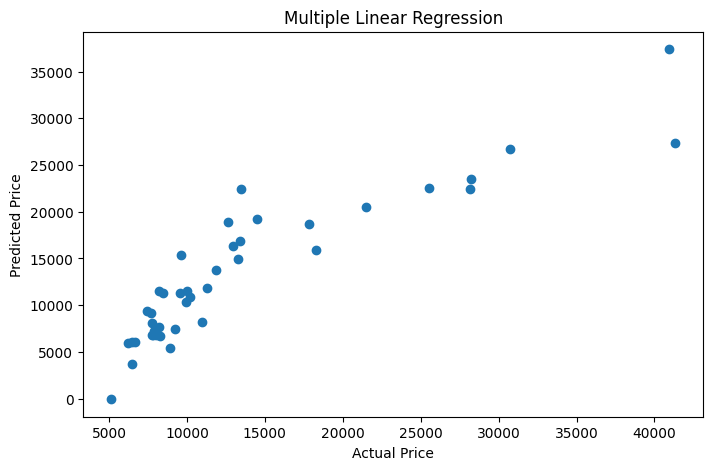

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")

plt.title("Multiple Linear Regression")

plt.show()

In [ ]:
print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

Intercept: -11642.135398748127
Coefficients: [  80.71321906   47.48173054    4.08262146 -114.18813742   69.24073235]


In [ ]:
df = pd.read_csv("CarPrice_Assignment.csv")

print(df.head())

   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrpm citympg  \

In [ ]:
X = df[["enginesize"]]

y = df["price"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [ ]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)

X_test_poly = poly.transform(X_test)

In [ ]:
model_poly = LinearRegression()

model_poly.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
y_pred_poly = model_poly.predict(X_test_poly)

print(y_pred_poly)

[27016.63784966 14105.91865063 12224.90480465 12396.52170581
 22796.29964116  8243.73261517 10501.96372615  8418.18147156
 10155.8979686   8243.73261517 14955.99980474  8418.18147156
 15633.84841525 12568.01547849 42324.52966301  7369.64140591
  1881.57021225 18325.54229921 12568.01547849 10155.8979686
 12568.01547849 22468.21064284  8243.73261517  7369.64140591
  7019.14302279 27016.63784966 16646.92747637 15803.00274666
  8243.73261517 15803.00274666 22796.29964116  7019.14302279
  7369.64140591 21150.92951006  8418.18147156 22796.29964116
 10155.8979686   3487.07092426  7019.14302279 18325.54229921
 10155.8979686 ]


In [ ]:
mae_poly = mean_absolute_error(y_test, y_pred_poly)

mse_poly = mean_squared_error(y_test, y_pred_poly)

rmse_poly = np.sqrt(mse_poly)

r2_poly = r2_score(y_test, y_pred_poly)

print("Polynomial Regression Results")

print("MAE:", mae_poly)
print("MSE:", mse_poly)
print("RMSE:", rmse_poly)
print("R2 Score:", r2_poly)

Polynomial Regression Results
MAE: 2734.311710881511
MSE: 15637882.192005608
RMSE: 3954.47622220764
R2 Score: 0.8019117595258543


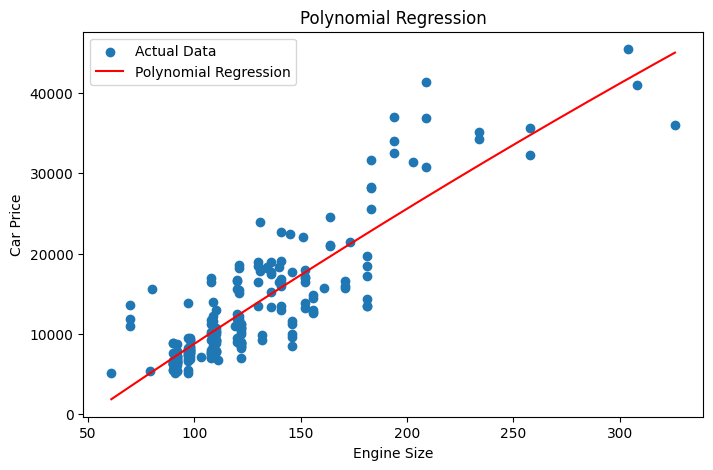

In [ ]:
X_curve = pd.DataFrame({
    "enginesize": np.linspace(
        X["enginesize"].min(),
        X["enginesize"].max(),
        200
    )
})

X_curve_poly = poly.transform(X_curve)

y_curve = model_poly.predict(X_curve_poly)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label="Actual Data")

plt.plot(
    X_curve["enginesize"],
    y_curve,
    color="red",
    label="Polynomial Regression"
)

plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.title("Polynomial Regression")
plt.legend()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import plot_tree

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
df = pd.read_csv("CarPrice_Assignment.csv")

print(df.head())

   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrpm citympg  \

In [ ]:
X = df[["enginesize"]]

y = df["price"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model_tree = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

In [ ]:
model_tree.fit(X_train, y_train)

DecisionTreeRegressor(max_depth=4, random_state=42)

In [ ]:
y_pred_tree = model_tree.predict(X_test)

print(y_pred_tree)

[34784.         17312.1        12036.70833333 12036.70833333
 31600.          7221.82291667  9918.79310345  7221.82291667
  9918.79310345  7221.82291667 17312.1         7221.82291667
 17312.1        12036.70833333 45400.          7221.82291667
 11633.5        14544.0625     12036.70833333  9918.79310345
 12036.70833333 16430.125       7221.82291667  7221.82291667
  7221.82291667 34784.         14544.0625     17312.1
  7221.82291667 17312.1        31600.          7221.82291667
  7221.82291667 16430.125       7221.82291667 31600.
  9918.79310345 11633.5         7221.82291667 14544.0625
  9918.79310345]


In [ ]:
mae_tree = mean_absolute_error(
    y_test, y_pred_tree
)

mse_tree = mean_squared_error(
    y_test, y_pred_tree
)

rmse_tree = np.sqrt(mse_tree)

r2_tree = r2_score(
    y_test, y_pred_tree
)

print("Decision Tree Results")

print("MAE:", mae_tree)
print("MSE:", mse_tree)
print("RMSE:", rmse_tree)
print("R2 Score:", r2_tree)

Decision Tree Results
MAE: 2288.697279997197
MSE: 8725402.07255283
RMSE: 2953.87915672812
R2 Score: 0.8894735538508504


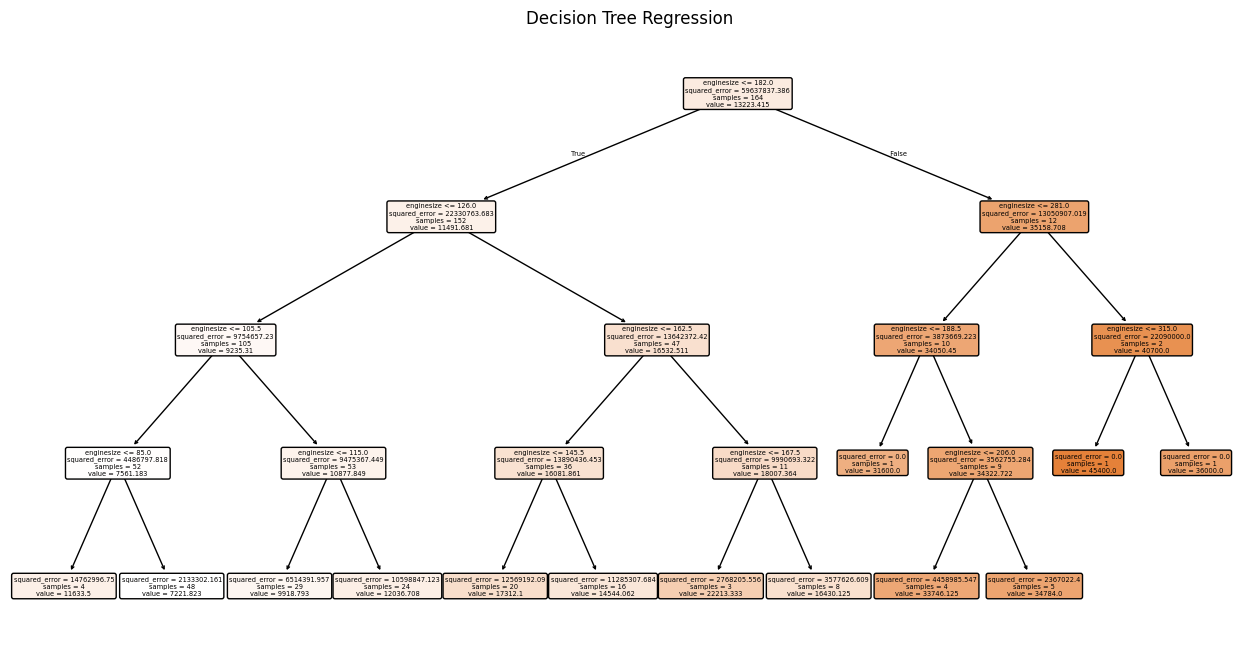

In [ ]:
plt.figure(figsize=(16, 8))

plot_tree(
    model_tree,
    feature_names=["enginesize"],
    filled=True,
    rounded=True
)

plt.title("Decision Tree Regression")

plt.show()

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [ ]:
df = pd.read_csv("CarPrice_Assignment.csv")

print(df.head())

   car_ID  symboling                   CarName fueltype aspiration doornumber  \
0       1          3        alfa-romero giulia      gas        std        two   
1       2          3       alfa-romero stelvio      gas        std        two   
2       3          1  alfa-romero Quadrifoglio      gas        std        two   
3       4          2               audi 100 ls      gas        std       four   
4       5          2                audi 100ls      gas        std       four   

       carbody drivewheel enginelocation  wheelbase  ...  enginesize  \
0  convertible        rwd          front       88.6  ...         130   
1  convertible        rwd          front       88.6  ...         130   
2    hatchback        rwd          front       94.5  ...         152   
3        sedan        fwd          front       99.8  ...         109   
4        sedan        4wd          front       99.4  ...         136   

   fuelsystem  boreratio  stroke compressionratio horsepower  peakrpm citympg  \

In [ ]:
y = df["price"]

X_simple = df[["enginesize"]]

X_multiple = df[[
    "enginesize",
    "horsepower",
    "curbweight",
    "citympg",
    "highwaympg"
]]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_simple,
    y,
    test_size=0.2,
    random_state=42
)

Xm_train, Xm_test, _, _ = train_test_split(
    X_multiple,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
model1 = LinearRegression()

model1.fit(X_train, y_train)

pred1 = model1.predict(X_test)

In [ ]:
model2 = LinearRegression()

model2.fit(Xm_train, y_train)

pred2 = model2.predict(Xm_test)

In [ ]:
model3 = make_pipeline(
    PolynomialFeatures(degree=2),
    LinearRegression()
)

model3.fit(X_train, y_train)

pred3 = model3.predict(X_test)

In [ ]:
model4 = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

model4.fit(X_train, y_train)

pred4 = model4.predict(X_test)

In [ ]:
results = []

models_predictions = {
    "Simple Linear Regression": pred1,
    "Multiple Linear Regression": pred2,
    "Polynomial Regression": pred3,
    "Decision Tree Regression": pred4
}

for name, predictions in models_predictions.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

comparison = pd.DataFrame(results)

print(comparison.round(3))

                    Algorithm       MAE           MSE      RMSE  R2 Score
0    Simple Linear Regression  2748.695  1.546546e+07  3932.615     0.804
1  Multiple Linear Regression  2766.595  1.452822e+07  3811.590     0.816
2       Polynomial Regression  2734.312  1.563788e+07  3954.476     0.802
3    Decision Tree Regression  2288.697  8.725402e+06  2953.879     0.889


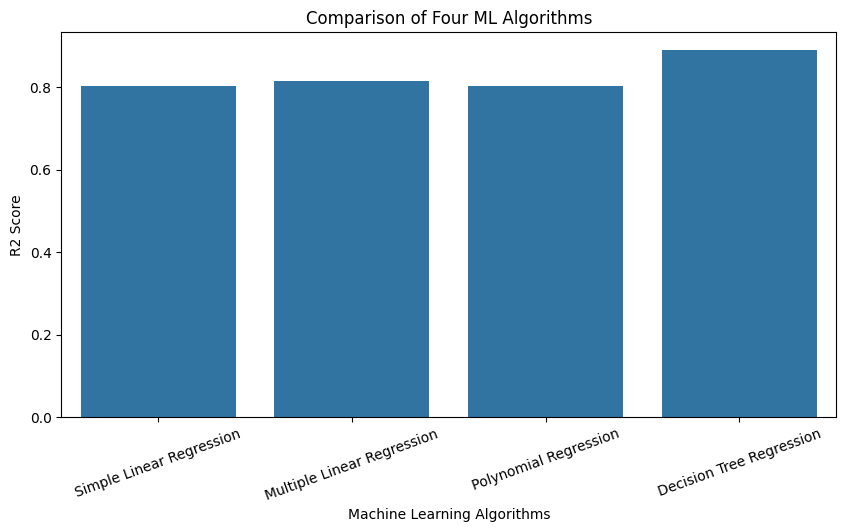

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=comparison,
    x="Algorithm",
    y="R2 Score"
)

plt.title("Comparison of Four ML Algorithms")

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("R2 Score")

plt.xticks(rotation=20)

plt.show()

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
import pandas as pd

X = df[["enginesize"]]
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = DecisionTreeRegressor(
    max_depth=4, random_state=42
)

model.fit(X_train, y_train)

predicted = model.predict(X_test)

result = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": predicted
})

result["Prediction Error"] = (
    result["Actual Price"] - result["Predicted Price"]
)

result["Absolute Error"] = result["Prediction Error"].abs()

print(result)

     Actual Price  Predicted Price  Prediction Error  Absolute Error
15      30760.000     34784.000000      -4024.000000     4024.000000
9       17859.167     17312.100000        547.067000      547.067000
100      9549.000     12036.708333      -2487.708333     2487.708333
132     11850.000     12036.708333       -186.708333      186.708333
68      28248.000     31600.000000      -3352.000000     3352.000000
95       7799.000      7221.822917        577.177083      577.177083
159      7788.000      9918.793103      -2130.793103     2130.793103
162      9258.000      7221.822917       2036.177083     2036.177083
147     10198.000      9918.793103        279.206897      279.206897
182      7775.000      7221.822917        553.177083      553.177083
191     13295.000     17312.100000      -4017.100000     4017.100000
164      8238.000      7221.822917       1016.177083     1016.177083
65      18280.000     17312.100000        967.900000      967.900000
175      9988.000     12036.708333

In [ ]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# Step 1: Load the dataset
df = pd.read_csv("CarPrice_Assignment.csv")

# Step 2: Select target variable
y = df["price"]

# Step 3: Split the dataset
# Use the same split for all four models
indices = df.index

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

y_train = y.loc[train_idx]
y_test = y.loc[test_idx]

# Step 4: Define the four regression models

models = {
    "Simple Linear Regression": (
        LinearRegression(),
        ["enginesize"]
    ),

    "Multiple Linear Regression": (
        LinearRegression(),
        ["enginesize", "horsepower", "curbweight",
         "citympg", "highwaympg"]
    ),

    "Polynomial Regression": (
        make_pipeline(
            PolynomialFeatures(degree=2),
            LinearRegression()
        ),
        ["enginesize"]
    ),

    "Decision Tree Regression": (
        DecisionTreeRegressor(
            max_depth=4,
            random_state=42
        ),
        ["enginesize"]
    )
}

# Step 5: Calculate R2 score
results = []

for name, (model, features) in models.items():

    X_train = df.loc[train_idx, features]
    X_test = df.loc[test_idx, features]

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    score = r2_score(y_test, predictions)

    accuracy_percentage = score * 100

    results.append({
        "Algorithm": name,
        "R2 Score": round(score, 4),
        "Performance (%)": round(accuracy_percentage, 2)
    })

# Step 6: Display results
result_df = pd.DataFrame(results)

print("\nREGRESSION MODEL PERFORMANCE")
print(result_df)

# Step 7: Find the best model
best_model = result_df.loc[
    result_df["R2 Score"].idxmax()
]

print("\nBest Performing Model:")
print(best_model["Algorithm"])

print("R2 Score:",
      best_model["Performance (%)"], "%")


REGRESSION MODEL PERFORMANCE
                    Algorithm  R2 Score  Performance (%)
0    Simple Linear Regression    0.8041            80.41
1  Multiple Linear Regression    0.8160            81.60
2       Polynomial Regression    0.8019            80.19
3    Decision Tree Regression    0.8895            88.95

Best Performing Model:
Decision Tree Regression
R2 Score: 88.95 %


In [ ]:
pip install joblib

In [ ]:
pip install pandas scikit-learn joblib

In [ ]:

import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score

# Step 1: Load dataset
df = pd.read_csv("CarPrice_Assignment.csv")

# Step 2: Select input and output
X = df[["enginesize"]]
y = df["price"]

# Step 3: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 4: Create model
model = DecisionTreeRegressor(
    max_depth=4,
    random_state=42
)

# Step 5: Train model
model.fit(X_train, y_train)

# Step 6: Test model
predictions = model.predict(X_test)

# Step 7: Calculate R2 score
score = r2_score(y_test, predictions)

print("Model R2 Score:", score * 100, "%")

# Step 8: Save trained model
joblib.dump(model, "car_price_model.pkl")

print("Model saved successfully!")


Model R2 Score: 88.94735538508503 %
Model saved successfully!


In [ ]:

import joblib
import pandas as pd

# Load saved model
model = joblib.load("car_price_model.pkl")

# Enter engine size
engine_size = 130

# Predict car price
prediction = model.predict(
    pd.DataFrame({"enginesize": [engine_size]})
)

print("Predicted Car Price:", prediction[0])


Predicted Car Price: 17312.1


In [ ]:
import joblib

# Save the trained model
joblib.dump(model, "car_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import os

print(os.getcwd())

/content
